Гипотезы:
1. Чем выше индекс массы тела, тем выше риск заболевания диабетом
2. Люди старше 45 лет чаще имеют гипертонию

Способы проверки гипотез:
1. Строим лог регрессию (ROC-AUC метрика)
2. Поделить на две возрастные группы, сравнить частоту

Таски:
1. Визуализации(  1.1 Heat-map
  1.2 ROC-AUC для регрессии
  1.3 Гистограммы распределений)
2. Подготовка данных

Подготовка данных

In [208]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score, roc_curve
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.contingency_tables import Table2x2

In [209]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [210]:
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

df = pd.read_csv("drive/MyDrive/diabetes_prediction_dataset.csv")
df = df[df["gender"].isin(["Female", "Male"])].dropna(subset=["bmi", "diabetes"]).copy()


In [211]:
df = df[df["gender"].isin(["Female", "Male"])]
df = df.dropna(subset=["bmi", "diabetes"])
print(df["diabetes"].value_counts(normalize=True))
print(df.groupby("diabetes")["bmi"].describe())

diabetes
0    0.914985
1    0.085015
Name: proportion, dtype: float64
            count       mean       std    min    25%    50%      75%    max
diabetes                                                                   
0         91482.0  26.887067  6.373428  10.01  23.24  27.32  28.8700  95.69
1          8500.0  31.988382  7.558371  10.98  27.32  29.97  35.9125  88.72


In [212]:
X = sm.add_constant(df["bmi"])
y = df["diabetes"]
model = sm.Logit(y, X).fit(disp=False)
print(model.summary())
OR = np.exp(model.params["bmi"])
print(f"OR на +1 кг/м²: {OR:.4f}")
ci = model.conf_int().loc["bmi"]
print(f"95% CI: [{np.exp(ci[0]):.4f}; {np.exp(ci[1]):.4f}]")

                           Logit Regression Results                           
Dep. Variable:               diabetes   No. Observations:                99982
Model:                          Logit   Df Residuals:                    99980
Method:                           MLE   Df Model:                            1
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                 0.06712
Time:                        08:44:46   Log-Likelihood:                -27128.
converged:                       True   LL-Null:                       -29080.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -5.1158      0.047   -107.707      0.000      -5.209      -5.023
bmi            0.0941      0.001     62.895      0.000       0.091       0.097
OR на +1 кг/м²: 1.0987
95% CI: [1.0955; 1.1019]


In [213]:
auc = roc_auc_score(y, df["bmi"])
print(f"AUC по одному ИМТ = {auc:.3f}")

AUC по одному ИМТ = 0.705


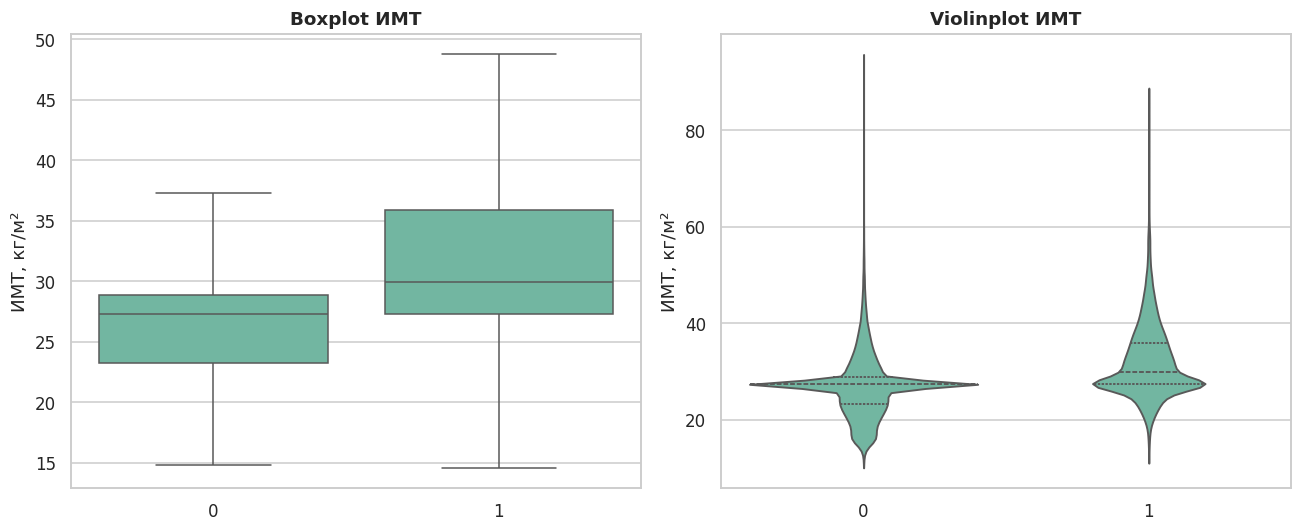

In [214]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="diabetes", y="bmi", ax=axes[0],
            showfliers=False)
axes[0].set_title("Boxplot ИМТ")
axes[0].set_xlabel("")
axes[0].set_ylabel("ИМТ, кг/м²")

sns.violinplot(data=df, x="diabetes", y="bmi", ax=axes[1],
               inner="quartile", cut=0)
axes[1].set_title("Violinplot ИМТ")
axes[1].set_xlabel("")
axes[1].set_ylabel("ИМТ, кг/м²")

plt.tight_layout()
plt.show()

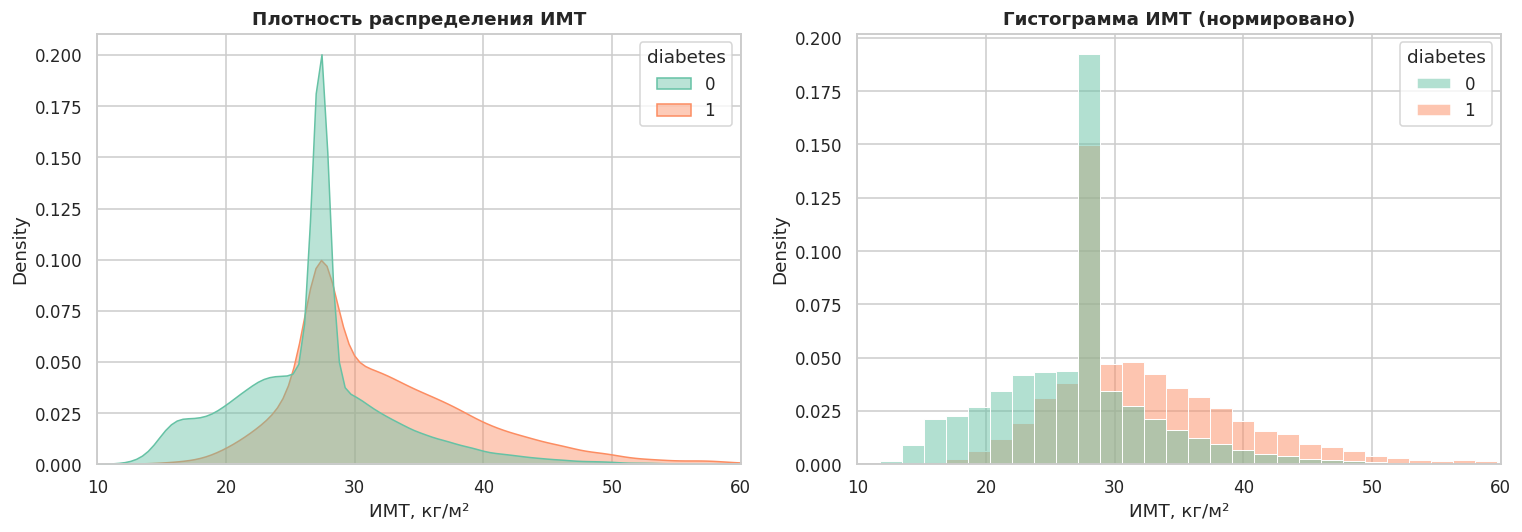

In [215]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KDE
sns.kdeplot(data=df, x="bmi", hue="diabetes", fill=True,
            common_norm=False, alpha=0.45, ax=axes[0])
axes[0].set_title("Плотность распределения ИМТ")
axes[0].set_xlabel("ИМТ, кг/м²")
axes[0].set_xlim(10, 60)

# Гистограмма с нормировкой (density)
sns.histplot(data=df, x="bmi", hue="diabetes", bins=50,
             stat="density", common_norm=False, alpha=0.5, ax=axes[1])
axes[1].set_title("Гистограмма ИМТ (нормировано)")
axes[1].set_xlabel("ИМТ, кг/м²")
axes[1].set_xlim(10, 60)

plt.tight_layout()
plt.show()

У пациентов с диабетом ИМТ статистически значимо выше: медиана и верхние квартили сдвинуты вправо, что указывает на систематический сдвиг всего распределения, а не на влияние отдельных выбросов. Наибольший сдвиг наблюдается в верхних квартилях, то есть в клинически рисковой зоне ожирения, что подтверждает гипотезу о росте риска с увеличением ИМТ. Одновременно у диабетиков шире разброс ИМТ — это говорит о гетерогенности группы и о том, что ИМТ является важным, но не единственным фактором риска.

**2. Исследование данных**

Разведочный анализ данных (EDA)

In [216]:
# Настройки отображения
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [217]:

# Первичный просмотр
print("Первые 5 строк:")
display(df.head())

print("\nИнформация о датафрейме:")
df.info()

Первые 5 строк:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



Информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
Index: 99982 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               99982 non-null  object 
 1   age                  99982 non-null  float64
 2   hypertension         99982 non-null  int64  
 3   heart_disease        99982 non-null  int64  
 4   smoking_history      99982 non-null  object 
 5   bmi                  99982 non-null  float64
 6   HbA1c_level          99982 non-null  float64
 7   blood_glucose_level  99982 non-null  int64  
 8   diabetes             99982 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 7.6+ MB


In [218]:
# размер и структура набора данных
print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
print("\nТипы данных:")
print(df.dtypes)

print("\nОписательная статистика (числовые признаки):")
display(df.describe().T)

print("\nОписательная статистика (категориальные признаки):")
display(df.describe(include='object').T)

Размер датасета: 99982 строк, 9 столбцов

Типы данных:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

Описательная статистика (числовые признаки):


,count,mean,std,min,25%,50%,75%,max
age,99982.0,41.888076,22.517206,0.08,24.00,43.00,60.00,80.00
hypertension,99982.0,0.074863,0.263172,0.00,0.00,0.00,0.00,1.00
heart_disease,99982.0,0.039427,0.194610,0.00,0.00,0.00,0.00,1.00
bmi,99982.0,27.320757,6.636853,10.01,23.63,27.32,29.58,95.69
HbA1c_level,99982.0,5.527529,1.070665,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,99982.0,138.057810,40.709469,80.00,100.00,140.00,159.00,300.00
diabetes,99982.0,0.085015,0.278906,0.00,0.00,0.00,0.00,1.00



Описательная статистика (категориальные признаки):


,count,unique,top,freq
gender,99982,2,Female,58552
smoking_history,99982,6,No Info,35810


In [219]:
# Разделение признаков по типам
categorical_features = ['gender', 'smoking_history']
binary_features = ['hypertension', 'heart_disease', 'diabetes']
numerical_features = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

print("Категориальные (номинальные):", categorical_features)
print("Бинарные (0/1):", binary_features)
print("Числовые (непрерывные):", numerical_features)

Категориальные (номинальные): ['gender', 'smoking_history']
Бинарные (0/1): ['hypertension', 'heart_disease', 'diabetes']
Числовые (непрерывные): ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']


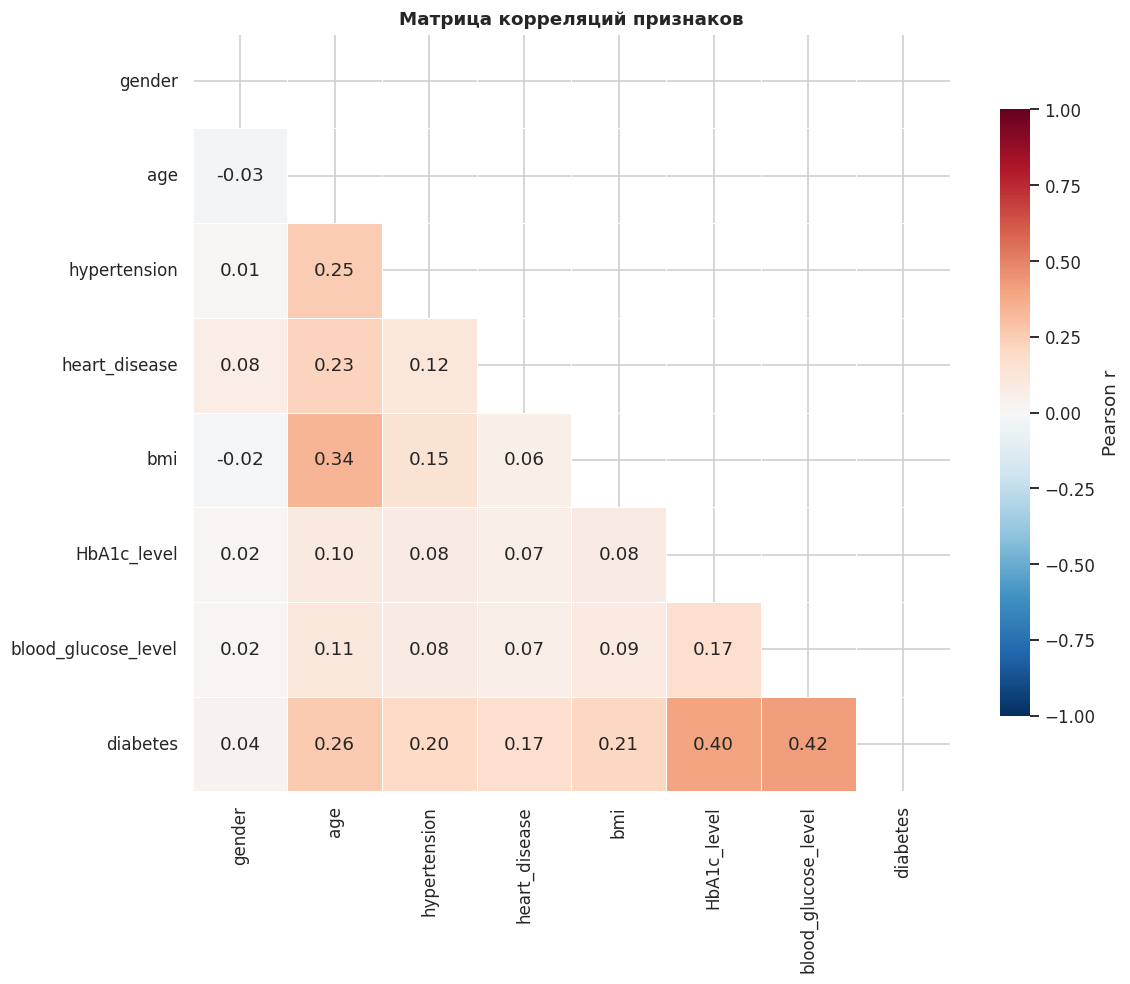

In [220]:
df = df[df["gender"].isin(["Female", "Male"])].copy()

df["gender"] = (df["gender"] == "Male").astype(int)
df = pd.get_dummies(df, columns=["smoking_history"],
                    prefix="smoke", drop_first=True)


df_num = df.select_dtypes(include=[np.number])

corr = df_num.corr(method="pearson")
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8, "label": "Pearson r"})
plt.title("Матрица корреляций признаков")
plt.tight_layout()
plt.show()

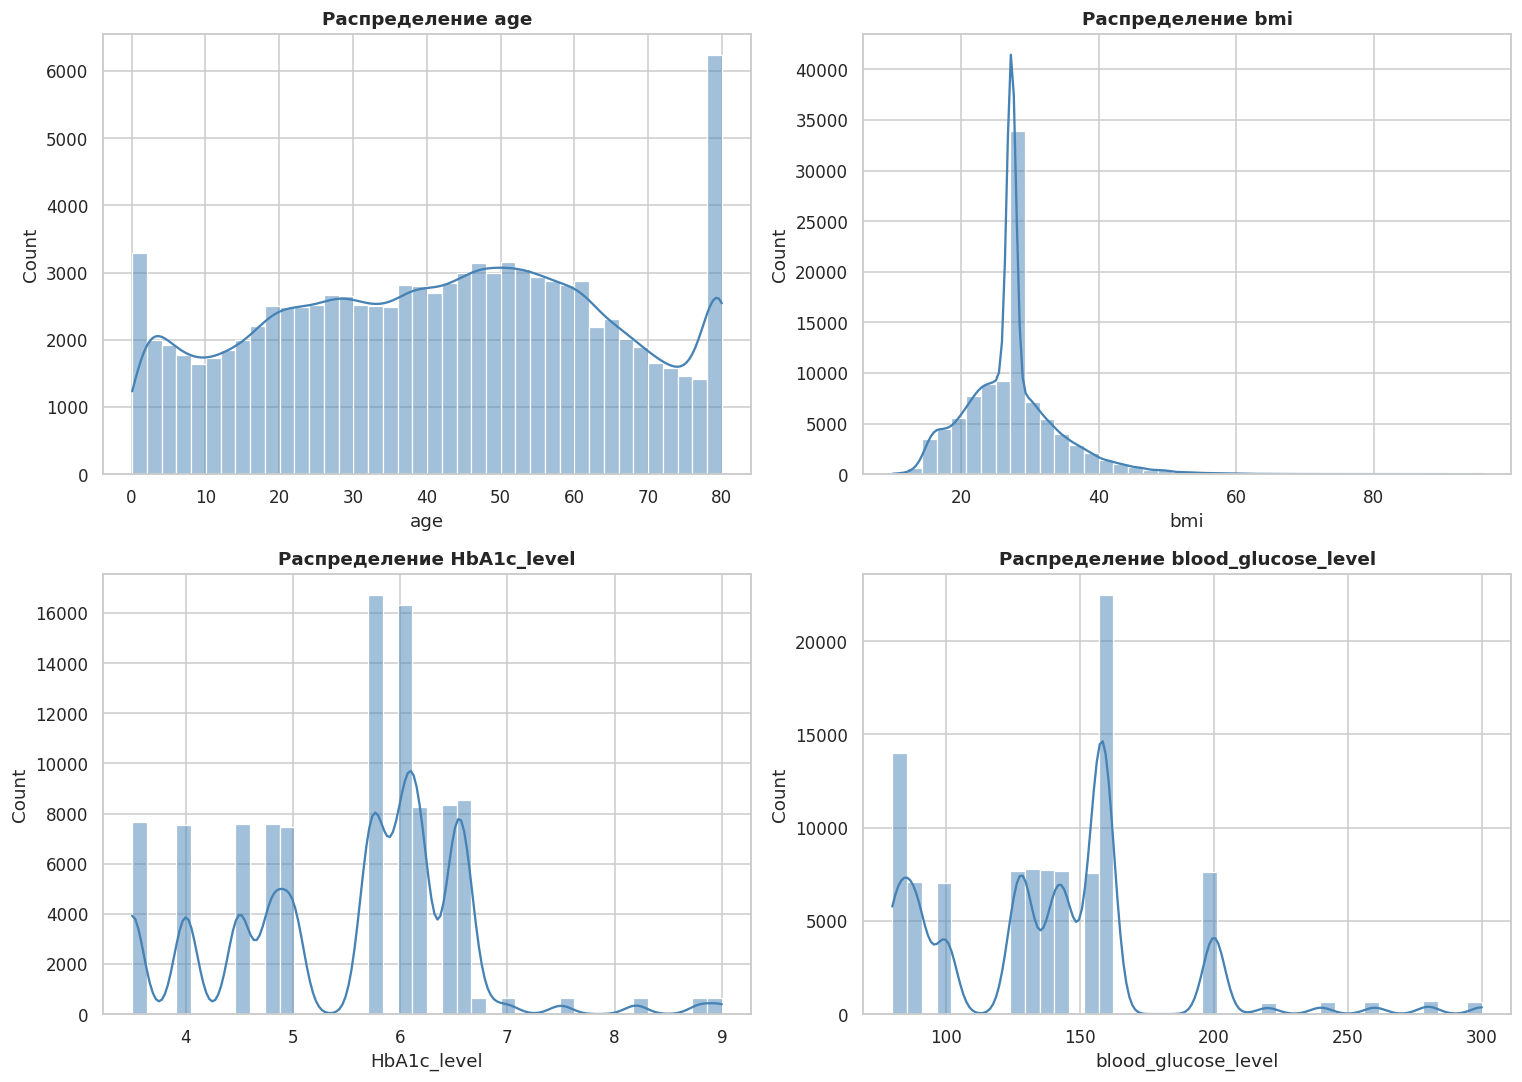

In [221]:
#Распределение числовых признаков
num_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col], kde=True, bins=40, ax=ax, color='steelblue')
    ax.set_title(f'Распределение {col}')
plt.tight_layout()
plt.show()

In [222]:
# Пропуски и дубликаты
print("Пропуски по столбцам:")
print(df.isnull().sum())

duplicates = df.duplicated().sum()
print(f"\nКоличество полных дубликатов: {duplicates} ({duplicates/len(df)*100:.2f}%)")

# Удаление дубликатов
df = df.drop_duplicates().reset_index(drop=True)
print(f"Размер после удаления дубликатов: {df.shape}")


Пропуски по столбцам:
gender                 0
age                    0
hypertension           0
heart_disease          0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
smoke_current          0
smoke_ever             0
smoke_former           0
smoke_never            0
smoke_not current      0
dtype: int64

Количество полных дубликатов: 3854 (3.85%)
Размер после удаления дубликатов: (96128, 13)


In [223]:
# Проверка нулевых/аномальных значений
print("Минимальные значения числовых признаков:")
print(df[num_cols].min())
print("\nМаксимальные значения числовых признаков:")
print(df[num_cols].max())

# Проверка возраста = 0
print(f"\nЗаписей с age == 0: {(df['age'] == 0).sum()}")
print(f"Записей с bmi == 0: {(df['bmi'] == 0).sum()}")

# IQR-метод для поиска выбросов
def iqr_outliers(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return ((data[col] < lower) | (data[col] > upper)).sum()

print("\nКоличество выбросов (IQR-метод):")
for col in num_cols:
    print(f"  {col}: {iqr_outliers(df, col)}")

Минимальные значения числовых признаков:
age                     0.08
bmi                    10.01
HbA1c_level             3.50
blood_glucose_level    80.00
dtype: float64

Максимальные значения числовых признаков:
age                     80.00
bmi                     95.69
HbA1c_level              9.00
blood_glucose_level    300.00
dtype: float64

Записей с age == 0: 0
Записей с bmi == 0: 0

Количество выбросов (IQR-метод):
  age: 0
  bmi: 5354
  HbA1c_level: 1312
  blood_glucose_level: 2031


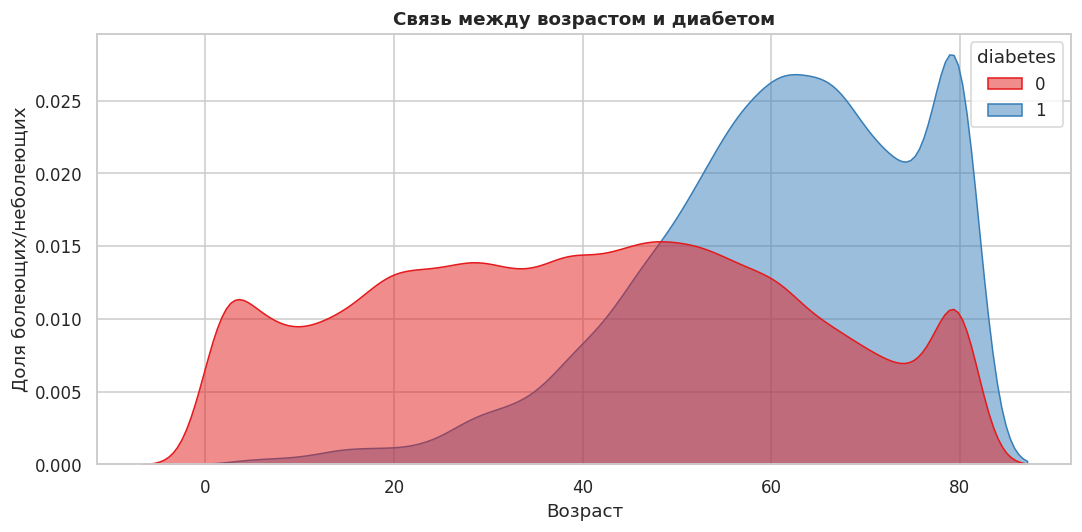

In [224]:
# Связи между признаками
# В каком возрасте риск диабета выше?
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df, x='age', hue='diabetes', fill=True, common_norm=False,
            palette='Set1', alpha=0.5)
plt.title('Связь между возрастом и диабетом')
plt.xlabel('Возраст')
plt.ylabel('Доля болеющих/неболеющих')
plt.tight_layout()
plt.show()

# Доля больных по возрастным группам
df['age_group'] = pd.cut(df['age'], bins=[0, 18, 30, 45, 60, 100],
                         labels=['<18', '18-30', '30-45', '45-60', '60+'])
age_diabetes = df.groupby('age_group', observed=True)['diabetes'].mean() * 100



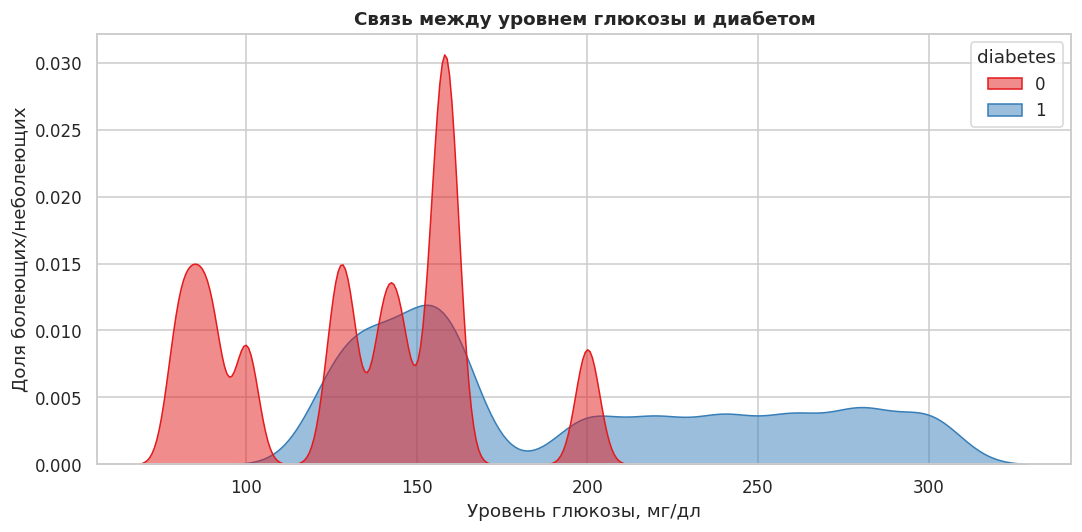

In [225]:
# Как распределён уровень глюкозы при диабете и без?
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df, x='blood_glucose_level', hue='diabetes', fill=True,
            common_norm=False, palette='Set1', alpha=0.5)
plt.title('Связь между уровнем глюкозы и диабетом')
plt.xlabel('Уровень глюкозы, мг/дл')
plt.ylabel('Доля болеющих/неболеющих')
plt.tight_layout()
plt.show()

Тест Фишера


In [226]:
df2 = pd.read_csv("drive/MyDrive/diabetes_prediction_dataset.csv")
df2 = df2[df2["gender"].isin(["Female", "Male"])].copy()

df2["hypertension"] = df2["hypertension"].astype(int)

df2["age_group"] = np.where(df2["age"] > 45, ">45 лет", "≤45 лет")

tab = pd.crosstab(df2["age_group"], df2["hypertension"])
tab = tab.reindex(["≤45 лет", ">45 лет"])
tab = tab.reindex(columns=[0, 1], fill_value=0)
print(tab)

a = tab.loc["≤45 лет", 0]
b = tab.loc["≤45 лет", 1]
c = tab.loc[">45 лет", 0]
d = tab.loc[">45 лет", 1]

table_target_first = np.array([[d, c], [b, a]])
OR, p = stats.fisher_exact(table_target_first, alternative="greater")
print(f"OR = {OR:.4f}, p (one-sided) = {p:.3e}")

hypertension      0     1
age_group                
≤45 лет       52886   978
>45 лет       39611  6507
OR = 8.8831, p (one-sided) = 0.000e+00


In [227]:
t = Table2x2(table_target_first)
print("OR =", t.oddsratio)
print("95% CI:", t.oddsratio_confint(method="normal"))

OR = 8.883147350313083
95% CI: (np.float64(8.295291614108173), np.float64(9.512662184553937))


Для проверки гипотезы о связи возраста и гипертонии была построена таблица сопряжённости. Доля лиц с гипертонией в группе старше 45 лет составила 14.1% против 1.8% в группе 45 лет и младше. Для оценки связи был применён точный тест Фишера (односторонний). Полученное отношение шансов (OR) составило 8.88 (95% ДИ: 8.29–9.51), p-value < 0.001 (в выводе программы 0.000e+00).

Это означает, что шансы иметь гипертонию у людей старше 45 лет статистически значимо и клинически существенно почти в 9 раз выше, чем у людей младше 45 лет. Полученный результат полностью подтверждает выдвинутую гипотезу